# Puntos Agrícolas

En esta libreta exploraremos los puntos agrícolas de las cartas de uso de suelo y vegetación.

## Serie I
Comenzaremos con la Serie 1. Extraeremos los datos e iremos complementando con el resto de Series.

In [16]:
from scripts.config import DATA_DIR
from zipfile import ZipFile
import os


MAPS_FOLDER = DATA_DIR / "pure" / "INEGI"
MAPS_ROUTE = DATA_DIR / "raw" / "INEGI"
maps = os.listdir(MAPS_FOLDER)

with ZipFile(MAPS_FOLDER / maps[0], 'r') as file:
    os.makedirs(MAPS_ROUTE / "m1", exist_ok=True)
    file.extractall(MAPS_ROUTE / "m1")


Una vez tengamos la información. Mostramos los puntos.

In [17]:
import geopandas as gpd

serie1_path = "/home/dusty/Documents/Repositories/proyecto_agronomia/data/raw/INEGI/m1/conjunto_de_datos/us250s1v_lcc.shp"
serie1 = gpd.read_file(serie1_path)

Una vez cargado el mapa. Veremos los valores

In [10]:
serie1['ENTIDAD'].unique().tolist()

['CUERPO DE AGUA',
 'PASTIZAL',
 'OTROS TIPOS DE VEGETACION',
 'LOCALIDAD',
 'AREA AGRICOLA',
 'BOSQUE',
 'MATORRAL',
 'AREA SIN VEGETACION',
 'SELVA']

Entonces, en la serie 1 vamos a filtrar por los valores de área agrícola.

In [11]:
agro1 = serie1[serie1['ENTIDAD'] == "AREA AGRICOLA"]
agro1.shape

(30276, 16)

Vemos que al hacer el filtro tenemos más de 30,000 regiones agrícolas.

<Axes: xlabel='x', ylabel='y'>

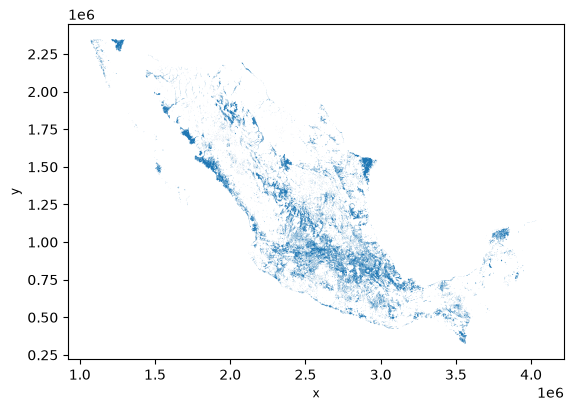

In [12]:
agro1.plot()

## Serie II

In [62]:
os.makedirs(MAPS_ROUTE/ "m2", exist_ok=True)
with ZipFile(MAPS_FOLDER / maps[1], 'r') as file:
    file.extractall(MAPS_ROUTE /"m2")

Vemos que la serie 2 tiene varios archivos. Vamos a revisar cada uno. 

In [21]:
serie2_folder = "/home/dusty/Documents/Repositories/proyecto_agronomia/data/raw/INEGI/m2/conjunto_de_datos"
serie2_maps = [f for f in os.listdir(serie2_folder) if f.endswith(".shp")]
serie2_maps

['us250s2a_lcc.shp',
 'us250s2c_lcc.shp',
 'us250s2e_lcc.shp',
 'us250s2n_lcc.shp',
 'us250s2v_lcc.shp']

In [36]:
maps201 = f"{serie2_folder}/{serie2_maps[0]}"
print(maps201)
map21 = gpd.read_file(maps201)
map21.shape

/home/dusty/Documents/Repositories/proyecto_agronomia/data/raw/INEGI/m2/conjunto_de_datos/us250s2a_lcc.shp


(6010, 15)

In [37]:
map21.head()

,AREA,PERIMETER,US250S2A_,US250S2A_I,FC,ENTIDAD,TIPO,CLAVE,UTMX,UTMY,LATITUD,LONGITUD,LCCX,LCCY,geometry
0,0.0,0.0,1,1,931,ACTIVIDAD PECUARIA,Bovinos,D1403,661575,1767468,"15d58'56.673""N","97d29'24.495""W",2984160,451871,POINT (2984128.796 451999.409)
1,0.0,0.0,2,2,931,ACTIVIDAD PECUARIA,Bovinos,D1403,667574,1764063,"15d57'4.449""N","97d26'3.592""W",2990260,448602,POINT (2990228.904 448730.545)
2,0.0,0.0,3,3,931,ACTIVIDAD PECUARIA,Bovinos,D1403,678474,1763895,"15d56'56.233""N","97d19'57.127""W",3001195,448700,POINT (3001163.729 448828.469)
3,0.0,0.0,4,4,931,ACTIVIDAD PECUARIA,Bovinos,E1302,484577,2202503,"19d55'11.96""N","105d8'50.512""W",2171640,883393,POINT (2171625.46 883492.255)
4,0.0,0.0,5,5,931,ACTIVIDAD PECUARIA,Bovinos,E1302,488261,2198391,"19d52'58.273""N","105d6'43.693""W",2175226,879217,POINT (2175211.853 879316.503)


Vemos que esto corresponde a la actividad pecuaria. Entonces, debemos buscar el agricola

In [46]:
maps202 = f"{serie2_folder}/{serie2_maps[3]}"
print(maps202)
map22 = gpd.read_file(maps202)
map22.shape

/home/dusty/Documents/Repositories/proyecto_agronomia/data/raw/INEGI/m2/conjunto_de_datos/us250s2n_lcc.shp


(2729, 8)

In [47]:
map22['ENTIDAD'].unique()

<ArrowStringArray>
['AGRICULTURA NOMADA', 'no aplica']
Length: 2, dtype: str

In [48]:
maps203 = f"{serie2_folder}/{serie2_maps[4]}"
print(maps203)
map23 = gpd.read_file(maps203)
map23.shape

/home/dusty/Documents/Repositories/proyecto_agronomia/data/raw/INEGI/m2/conjunto_de_datos/us250s2v_lcc.shp


(139153, 15)

In [49]:
map23['ENTIDAD'].unique()

<ArrowStringArray>
[          'PAIS EXTRANJERO',                 'LOCALIDAD',
                  'PASTIZAL', 'OTROS TIPOS DE VEGETACION',
             'AREA AGRICOLA',                    'BOSQUE',
                  'MATORRAL',            'CUERPO DE AGUA',
       'AREA SIN VEGETACION',                     'SELVA']
Length: 10, dtype: str

Ahora juntaremos y filtraremos la parte agricola.

In [61]:
import pandas as pd

agro2 = map23[map23['ENTIDAD'] == "AREA AGRICOLA"]
print(agro2.shape)

print(agro2.columns)
print(map22.columns)
agro2 = pd.concat([agro2, map22])
print(agro2.shape)

(27230, 15)
Index(['AREA', 'PERIMETER', 'US250S2V_', 'US250S2V_I', 'FC', 'CLAVEFOT',
       'ENTIDAD', 'TIPO', 'FISONOMIA', 'VEG_SEC', 'EROSION', 'CULT_PRI',
       'CULT_SEC', 'CULT_TER', 'geometry'],
      dtype='str')
Index(['AREA', 'PERIMETER', 'US250S2N_', 'US250S2N_I', 'FC', 'CLAVEFOT',
       'ENTIDAD', 'geometry'],
      dtype='str')
(29959, 17)


<Axes: xlabel='x', ylabel='y'>

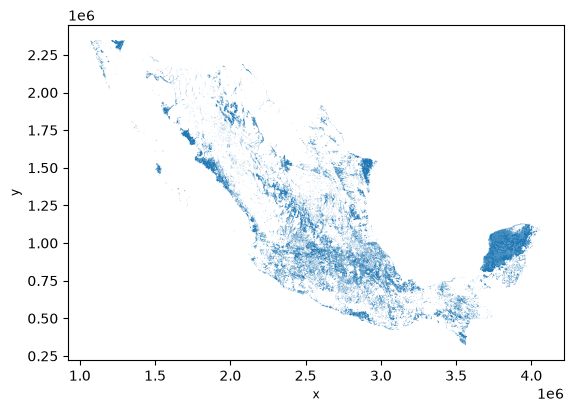

In [58]:
agro2.plot()

### Serie I vs Serie II.

Notemos que los datos no son los mismos. 

In [63]:
agro1.shape, agro2.shape

((30276, 16), (29959, 17))

Para construir unos datos. Partiremos construyendo un conjutno de puntos a partir de Serie I. En nuestro caso, usaremos el centro de cada región.

In [68]:
agro1['SerieIPoints'] = agro1['geometry'].centroid
agro2['SerieIIPoints'] = agro2['geometry'].centroid

In [82]:
agroset1 = [p.coords[0] for p in agro1['SerieIPoints']]
agroset2 = [p.coords[0] for p in agro2['SerieIIPoints']]


In [93]:
import numpy as np

def euclidean(p1, p2):
    gy = p2[1] - p1[1]
    gx = p2[0] - p1[0]
    dis = (gy ** 2 + gx**2 ) ** (0.5)
    return dis

v = np.zeros((len(agroset1), len(agroset2)))

k=0
for k1, p1 in enumerate(agroset1):
    for k2, p2 in enumerate(agroset2):
        v[k1, k2] = euclidean(p1, p2)
    print(k)
    k+=1
    

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239
240
241
242
243
244
245
246
247
248
249
250
251
252
253
254
255
256
257
258
259
260
261
262
263
264
265
266
267
268
269
270
271
272
273
274
275
276
27

In [94]:
v

array([[2.97010375e+04, 3.25356135e+04, 1.51640746e+05, ...,
        3.09764016e+06, 3.13890508e+06, 3.05367528e+06],
       [1.96502067e+04, 2.25475850e+04, 1.41550957e+05, ...,
        3.08890527e+06, 3.13018508e+06, 3.04410239e+06],
       [3.39651140e+03, 2.46051263e+02, 1.19202443e+05, ...,
        3.07143645e+06, 3.11275892e+06, 3.02403496e+06],
       ...,
       [3.14894865e+06, 3.14755044e+06, 3.04347683e+06, ...,
        9.62147680e+04, 6.11942516e+04, 6.98043373e+05],
       [3.15509697e+06, 3.15369565e+06, 3.04955623e+06, ...,
        9.92263794e+04, 6.22894019e+04, 6.96535803e+05],
       [3.15959169e+06, 3.15819280e+06, 3.05410304e+06, ...,
        1.04452430e+05, 6.72861822e+04, 7.00419316e+05]],
      shape=(30276, 29959))